<a href="https://colab.research.google.com/github/apkh1116/strong-kheer-191531/blob/apkh/%EC%9E%A5%EA%B7%9C%ED%98%84_3_%EB%B6%84%EB%A5%98_%EB%AA%A8%EB%8D%B8_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#[문제] 펭귄 종을 분류하는 모델을 구현해 보자.(교과서 110p)

#[1단계] 데이터 수집하기 (penguins_size.csv)

In [ ]:
#1.데이터 불러오기
import pandas as pd
df=pd.read_csv('penguins_size.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [ ]:
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


#[2단계] 데이터 전처리

In [ ]:
#2.결측치 처리하기
df.isnull().sum()

,0
species,0
island,0
culmen_length_mm,2
culmen_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,10


In [ ]:
#결측치 행 삭제
df.dropna(axis=0, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 334 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            334 non-null    object 
 1   island             334 non-null    object 
 2   culmen_length_mm   334 non-null    float64
 3   culmen_depth_mm    334 non-null    float64
 4   flipper_length_mm  334 non-null    float64
 5   body_mass_g        334 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 20.9+ KB


In [ ]:
#독립변수 (부리 길이, 부리 깊이, 날개 길이), 종속변수(종) 지정
X = df[['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm']]
y = df['species']

In [ ]:
#훈련데이터와 데스트데이터 분할(훈련데이터는 0.7, 70%) (random_state = 42)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size = 0.3, stratify = y)

#[3단계] 모델 생성하기

In [ ]:
#모델학습( fit() 함수)
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train) #모델 학습
#성능평가(훈련데이터 이용)
dt.score(X_train, y_train) #정확도를 구하는 함수: score()

1.0

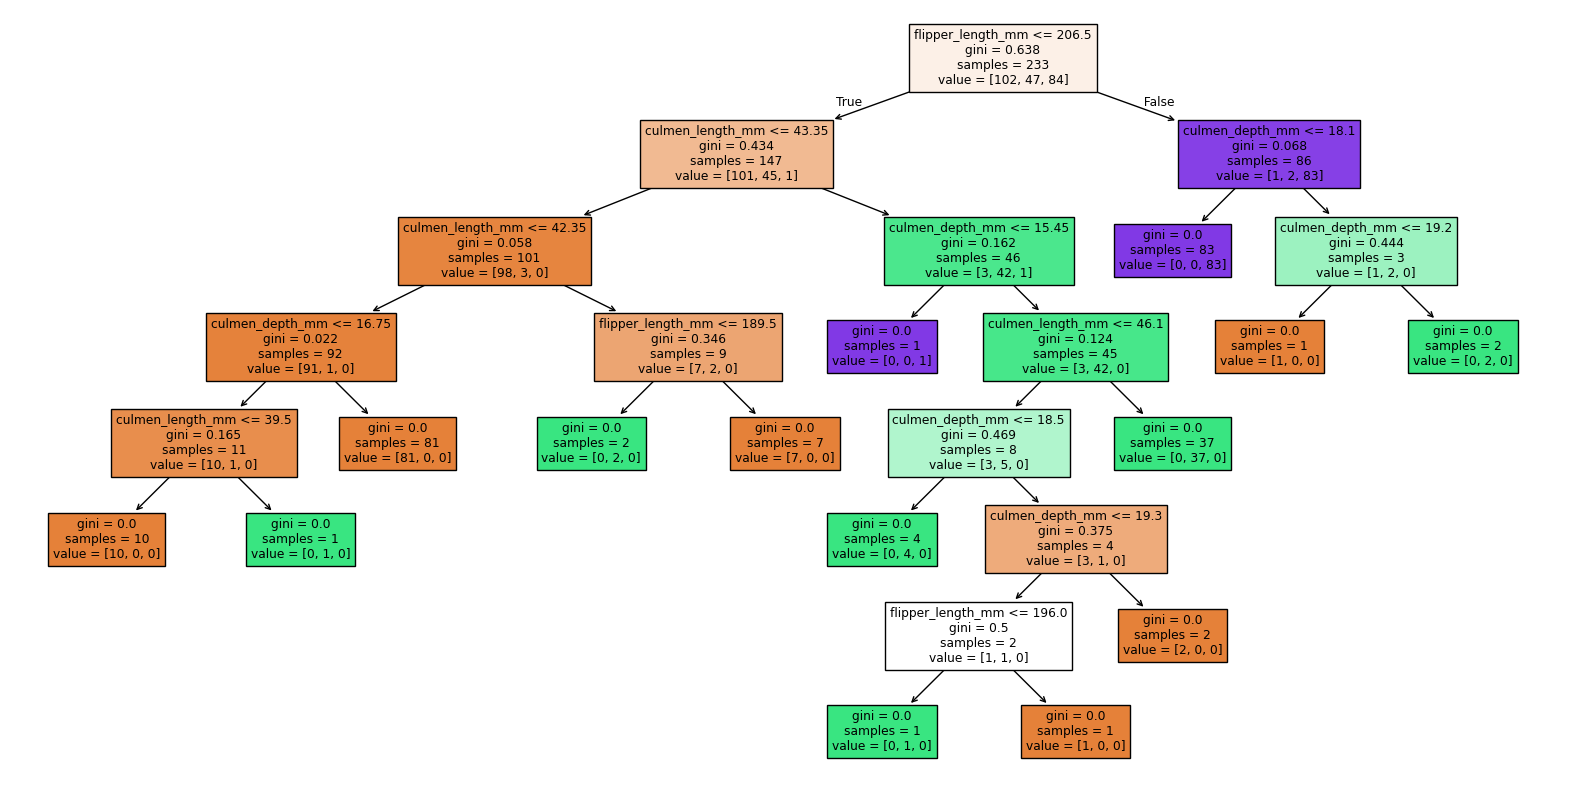

In [ ]:
#결정트리 시각화 (gini 개수: 다른 클래스(분류)가 섞여있는 개수(완전히 분류되지 x) --> gini 개수가 0이 될 때까지)
import matplotlib.pyplot as plt
from sklearn. tree import plot_tree
plt.figure(figsize=(20,10))
plot_tree(dt, feature_names = X.columns, filled=True)
plt.show()

#[4단계] 모델 평가하기

In [ ]:
#결과값 예측 (테스트 데이터로)
dt.predict(X_test)
#모델성능평가(테스트데이터)
# dt.score(X_test, y_test)

array(['Adelie', 'Adelie', 'Chinstrap', 'Gentoo', 'Gentoo', 'Adelie',
       'Gentoo', 'Adelie', 'Chinstrap', 'Gentoo', 'Adelie', 'Adelie',
       'Adelie', 'Gentoo', 'Gentoo', 'Gentoo', 'Adelie', 'Chinstrap',
       'Adelie', 'Chinstrap', 'Chinstrap', 'Adelie', 'Gentoo', 'Gentoo',
       'Gentoo', 'Adelie', 'Gentoo', 'Gentoo', 'Adelie', 'Gentoo',
       'Chinstrap', 'Gentoo', 'Adelie', 'Adelie', 'Gentoo', 'Adelie',
       'Gentoo', 'Gentoo', 'Gentoo', 'Gentoo', 'Adelie', 'Adelie',
       'Adelie', 'Gentoo', 'Adelie', 'Adelie', 'Chinstrap', 'Adelie',
       'Adelie', 'Gentoo', 'Gentoo', 'Adelie', 'Adelie', 'Chinstrap',
       'Chinstrap', 'Gentoo', 'Gentoo', 'Adelie', 'Adelie', 'Chinstrap',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Chinstrap', 'Gentoo',
       'Chinstrap', 'Chinstrap', 'Adelie', 'Chinstrap', 'Adelie',
       'Gentoo', 'Adelie', 'Adelie', 'Gentoo', 'Chinstrap', 'Gentoo',
       'Gentoo', 'Adelie', 'Adelie', 'Chinstrap', 'Gentoo', 'Gentoo',
       'Chinstrap', 'Ade

In [ ]:
#생성된 모델 파일 확인
import joblib
joblib.dump(dt, 'penguin_model.pkl')

['penguin_model.pkl']

In [ ]:
print('--- 펭귄 신체 치수 입력----')
length=float(input('부리길이>>'))
depth=float(input('부리깊이>>'))
flipper=float(input('날개길이>>'))

inputdf = pd.DataFrame([[length, depth,  flipper]],
                       columns=['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm'])

--- 펭귄 신체 치수 입력----
부리길이>>122
부리깊이>>45
날개길이>>23


In [ ]:
inputdf.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm
0,23.0,10.0,100.0


In [ ]:
model=joblib.load('penguin_model.pkl')
result = model.predict(inputdf)[0]
print(f'분류결과 : {result} 펭귄입니다.')

분류결과 : Chinstrap 펭귄입니다.
